<a href="https://colab.research.google.com/github/LevramUzo/gracce-groundwater-nigeria/blob/main/notebooks/01_data_acquisition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ==============================================================================
# PHASE 1: RE-INITIALIZATION & BOUNDARY TESTING OVER NIGERIA
# ==============================================================================
import ee
from google.colab import userdata

try:
    # 1. Fetch credentials securely from the local environment vault
    PROJECT_ID = userdata.get('GEE_PROJECT_ID')

    # 2. Authenticate the active workspace session
    print("Connecting to Google Cloud Ecosystem... Allow permission via pop-up.")
    ee.Authenticate()

    # 3. Mount the engine to your cloud profile
    ee.Initialize(project=PROJECT_ID)
    print(f"\n[SUCCESS] Google Earth Engine linked securely using project: {PROJECT_ID}")

    # 4. Load the Global International Boundaries database and isolate Nigeria
    global_boundaries = ee.FeatureCollection("USDOS/LSIB_SIMPLE/2017")
    nigeria_boundary = global_boundaries.filter(ee.Filter.eq('country_na', 'Nigeria'))

    # 5. Force the cloud geometry area calculation to process instantly
    nigeria_area_m2 = nigeria_boundary.geometry().area(maxError=1)
    nigeria_area_km2 = nigeria_area_m2.divide(1e6).getInfo()

    print("\n" + "="*55)
    print(f"NATIONAL STUDY AREA BOUNDARY ACTIVE")
    print("="*55)
    print(f"Target Boundary Region : Federal Republic of Nigeria")
    print(f"Calculated Basin Area  : {nigeria_area_km2:,.2f} km²")
    print("="*55 + "\2n")

except Exception as e:
    print(f"\n[ERROR]: Setup failed at re-initialization.")
    print(f"Details: {e}")


Connecting to Google Cloud Ecosystem... Allow permission via pop-up.

[SUCCESS] Google Earth Engine linked securely using project: weather-app-492314

NATIONAL STUDY AREA BOUNDARY ACTIVE
Target Boundary Region : Federal Republic of Nigeria
Calculated Basin Area  : 912,554.10 km²
=======================================================n


In [2]:
# ==============================================================================
# STEP 2.2: HYDROCLIMATIC PREDICTOR EXTRACTION (CHIRPS & MODIS LST)
# ==============================================================================
import ee
import pandas as pd

try:
    # 1. Reference our Nigeria boundary layer from the first cell
    global_boundaries = ee.FeatureCollection("USDOS/LSIB_SIMPLE/2017")
    nigeria = global_boundaries.filter(ee.Filter.eq('country_na', 'Nigeria'))

    # Define our temporal research window (2003 - 2016)
    START_DATE = '2003-01-01'
    END_DATE = '2016-12-31'

    print("Step 1/3: Accessing Climate Catalogs inside Earth Engine...")

    # 2. Ingest the CHIRPS High-Resolution Precipitation Dataset
    chirps_collection = ee.ImageCollection("UCSB-CHG/CHIRPS/DAILY") \
        .filterDate(START_DATE, END_DATE) \
        .select('precipitation')

    # 3. Ingest the MODIS Land Surface Temperature Dataset (Daytime)
    modis_lst_collection = ee.ImageCollection("MODIS/061/MOD11A1") \
        .filterDate(START_DATE, END_DATE) \
        .select('LST_Day_1km')

    # 4. Define an extraction function to process monthly blocks over Nigeria
    def extract_monthly_climate(year, month):
        # Establish month-specific date bounds
        start = ee.Date.fromYMD(year, month, 1)
        end = start.advance(1, 'month')

        # Calculate monthly totals for Rainfall and monthly averages for Temperature
        monthly_rain = chirps_collection.filterDate(start, end).sum()
        monthly_temp = modis_lst_collection.filterDate(start, end).mean()

        # Flatten pixels inside Nigeria down to national numeric values
        rain_val = monthly_rain.reduceRegion(
            reducer=ee.Reducer.mean(), geometry=nigeria.geometry(), scale=5500, maxPixels=1e9
        ).get('precipitation')

        temp_val = monthly_temp.reduceRegion(
            reducer=ee.Reducer.mean(), geometry=nigeria.geometry(), scale=5500, maxPixels=1e9
        ).get('LST_Day_1km')

        # Convert raw MODIS Kelvin values to readable Celsius degrees
        # (MODIS data is stored multiplied by a scale factor of 0.02)
        celsius_val = ee.Number(temp_val).multiply(0.02).subtract(273.15)

        # Return a structured record containing calendar keys
        date_str = start.format('YYYY-MM')
        return ee.Feature(None, {
            'date': date_str,
            'Rainfall_mm': rain_val,
            'LST_Celsius': ee.Algorithms.If(temp_val, celsius_val, None)
        })

    # 5. Build our timeline list loop to process through each year/month sequentially
    years = list(range(2003, 2017))
    months = list(range(1, 13))

    print("Step 2/3: Running spatial pixel reduction across Nigeria (This takes ~30 seconds)...")
    results_list = []

    for y in years:
        for m in months:
            # Execute cloud reduction commands for this month block
            feat = extract_monthly_climate(y, m)
            results_list.append(feat)

    # Resolve the cloud calculations and stream the clean text data back
    server_side_features = ee.FeatureCollection(results_list).getInfo()

    # 6. Reconstruct raw records into a highly scannable Data Frame
    compiled_records = [f['properties'] for f in server_side_features['features']]
    climate_df = pd.DataFrame(compiled_records)
    climate_df = climate_df.dropna().sort_values('date').reset_index(drop=True)

    print("\n" + "="*65)
    print("SUCCESS: NIGERIA CLIMATE MATRIX COMPILED")
    print("="*65)
    print(climate_df.head(12)) # Preview a full calendar year
    print("="*65)
    print(f"Total processed records: {len(climate_df)} calendar months.")
    print("="*65 + "\n")

except Exception as e:
    print(f"\n[ERROR]: Climate feature extraction failed.")
    print(f"Details: {e}")


Step 1/3: Accessing Climate Catalogs inside Earth Engine...
Step 2/3: Running spatial pixel reduction across Nigeria (This takes ~30 seconds)...

SUCCESS: NIGERIA CLIMATE MATRIX COMPILED
    LST_Celsius  Rainfall_mm     date
0     32.862381     6.546161  2003-01
1     35.399531    11.000401  2003-02
2     35.070512    16.483187  2003-03
3     37.283007    74.405237  2003-04
4     37.878470   112.640571  2003-05
5     29.155469   188.931344  2003-06
6     29.091259   216.928714  2003-07
7     28.365416   253.560656  2003-08
8     29.168214   231.016700  2003-09
9     31.794775    96.118767  2003-10
10    32.622224    20.124457  2003-11
11    31.650024     2.803890  2003-12
Total processed records: 168 calendar months.



In [3]:
# ==============================================================================
# STEP 2.3: TARGET VARIABLE EXTRACTION (NASA GRACE TWSA OVER NIGERIA)
# ==============================================================================
import ee
import pandas as pd

try:
    # 1. Fetch Nigeria's border using the global administrative layer
    global_boundaries = ee.FeatureCollection("USDOS/LSIB_SIMPLE/2017")
    nigeria = global_boundaries.filter(ee.Filter.eq('country_na', 'Nigeria'))

    # Define our matching temporal timeline (2003 - 2016)
    START_DATE = '2003-01-01'
    END_DATE = '2016-12-31'

    print("Accessing NASA GRACE Satellite Gravity Grids...")

    # 2. Ingest the official NASA GRACE Land Mass Grid collection (RL06 CSR)
    grace_collection = ee.ImageCollection("NASA/GRACE/MASS_GRIDS_V04/LAND") \
        .filterDate(START_DATE, END_DATE) \
        .select('lwe_thickness_csr')

    # 3. Create a regional function to calculate average water weight anomalies
    def extract_monthly_grace(image):
        # Reduce global pixels down to a single average thickness number inside Nigeria
        mean_val = image.reduceRegion(
            reducer=ee.Reducer.mean(),
            geometry=nigeria.geometry(),
            scale=25000, # Native resolution of the GRACE sensor footprint (25km)
            maxPixels=1e9
        ).get('lwe_thickness_csr')

        # Pull the year and month to match our climate table formatting
        date_str = image.date().format('YYYY-MM')

        return ee.Feature(None, {
            'date': date_str,
            'TWSA_mm': mean_val
        })

    print("Running geographic weight reductions across the Nigerian basin... Please wait.")

    # 4. Map the extraction loop across the historical timeline
    processed_features = grace_collection.map(extract_monthly_grace).getInfo()

    # 5. Build our structured data frame
    extracted_data = [f['properties'] for f in processed_features['features']]
    grace_df = pd.DataFrame(extracted_data)
    grace_df = grace_df.dropna().sort_values('date').reset_index(drop=True)

    print("\n" + "="*65)
    print("SUCCESS: NIGERIA GRACE TARGET ANOMALIES COMPILED")
    print("="*65)
    print(grace_df.head(12)) # Preview a full annual sequence
    print("="*65)
    print(f"Total compiled satellite observations: {len(grace_df)} months.")
    print("="*65 + "\n")

except Exception as e:
    print(f"\n[ERROR]: GRACE feature extraction failed.")
    print(f"Details: {e}")


Accessing NASA GRACE Satellite Gravity Grids...
Running geographic weight reductions across the Nigerian basin... Please wait.

SUCCESS: NIGERIA GRACE TARGET ANOMALIES COMPILED
     TWSA_mm     date
0  -0.091221  2003-01
1  -0.119114  2003-02
2  -0.133866  2003-03
3  -0.144336  2003-04
4  -0.013229  2003-06
5   0.055186  2003-07
6   0.144293  2003-08
7   0.133955  2003-09
8   0.070251  2003-10
9   0.017593  2003-11
10 -0.017884  2003-12
11 -0.061574  2004-02
Total compiled satellite observations: 150 months.



In [4]:
# ==============================================================================
# STEP 2.4: DATASET MERGING AND COORDINATION
# ==============================================================================
import pandas as pd

try:
    # Use pandas to link your climate data frame and GRACE data frame
    # We join them specifically on the 'date' column so everything lines up perfectly
    master_df = pd.merge(climate_df, grace_df, on='date', how='inner')

    # Sort the rows chronologically from past to present
    master_df = master_df.sort_values('date').reset_index(drop=True)

    print("\n" + "="*65)
    print("SUCCESS: MASTER HYDRO-MACHINE LEARNING DATASET MERGED")
    print("="*65)
    print(master_df.head(10)) # Preview a full lined-up year of records
    print("="*65)
    print(f"Total matching monthly rows coordinated: {len(master_df)} months.")
    print("="*65 + "\n")

    # Optional: Save a copy to your active Colab temporary files list
    master_df.to_csv('nigeria_groundwater_master.csv', index=False)
    print("[STATUS]: Master dataset saved locally as 'nigeria_groundwater_master.csv'")

except Exception as e:
    print(f"\n[ERROR]: Dataset merge failed.")
    print(f"Details: {e}")
    print("[FIX]: Make sure you ran both Cell 2 (Climate) and Cell 3 (GRACE) in this exact session.")



SUCCESS: MASTER HYDRO-MACHINE LEARNING DATASET MERGED
   LST_Celsius  Rainfall_mm     date   TWSA_mm
0    32.862381     6.546161  2003-01 -0.091221
1    35.399531    11.000401  2003-02 -0.119114
2    35.070512    16.483187  2003-03 -0.133866
3    37.283007    74.405237  2003-04 -0.144336
4    29.155469   188.931344  2003-06 -0.013229
5    29.091259   216.928714  2003-07  0.055186
6    28.365416   253.560656  2003-08  0.144293
7    29.168214   231.016700  2003-09  0.133955
8    31.794775    96.118767  2003-10  0.070251
9    32.622224    20.124457  2003-11  0.017593
Total matching monthly rows coordinated: 150 months.

[STATUS]: Master dataset saved locally as 'nigeria_groundwater_master.csv'


In [5]:
# ==============================================================================
# STEP 2.5: TOPOGRAPHIC PREDICTOR EXTRACTION (NASA SRTM ELEVATION & SLOPE)
# ==============================================================================
import ee

try:
    # 1. Fetch Nigeria vector boundaries
    global_boundaries = ee.FeatureCollection("USDOS/LSIB_SIMPLE/2017")
    nigeria = global_boundaries.filter(ee.Filter.eq('country_na', 'Nigeria'))

    print("Accessing NASA Digital Elevation Models...")

    # 2. Load the official NASA SRTM 30m Global Elevation Dataset
    srtm_elevation = ee.Image("USGS/SRTMGL1_003")

    # 3. Calculate topographic slope mathematically from the elevation layer
    srtm_slope = ee.Terrain.slope(srtm_elevation)

    # 4. Flatten pixels across Nigeria down to regional national averages
    elev_val = srtm_elevation.reduceRegion(
        reducer=ee.Reducer.mean(), geometry=nigeria.geometry(), scale=1000, maxPixels=1e9
    ).get('elevation')

    slope_val = srtm_slope.reduceRegion(
        reducer=ee.Reducer.mean(), geometry=nigeria.geometry(), scale=1000, maxPixels=1e9
    ).get('slope')

    print("\n" + "="*65)
    print("SUCCESS: NIGERIA TOPOGRAPHIC BASELINE EXTRACTED")
    print("="*65)
    print(f"Mean National Elevation : {elev_val.getInfo():,.2f} meters above sea level")
    print(f"Mean National Slope     : {slope_val.getInfo():,.2f} degrees steepness")
    print("="*65)
    print("[STATUS]: Static spatial terrain attributes initialized.")

except Exception as e:
    print(f"\n[ERROR]: Topographic extraction failed.")
    print(f"Details: {e}")


Accessing NASA Digital Elevation Models...

SUCCESS: NIGERIA TOPOGRAPHIC BASELINE EXTRACTED
Mean National Elevation : 330.24 meters above sea level
Mean National Slope     : 0.79 degrees steepness
[STATUS]: Static spatial terrain attributes initialized.


In [6]:
# ==============================================================================
# STEP 2.6: BROADCASTING STATIC TERRAIN VALUES TO THE MASTER MATRIX
# ==============================================================================
import pandas as pd

try:
    # 1. Read your terrain variables directly from your active variables
    mean_elevation = 330.24
    mean_slope = 0.79

    # 2. Assign these values as new columns across every single row of your matrix
    master_df['Elevation_m'] = mean_elevation
    master_df['Slope_deg'] = mean_slope

    # 3. Rearrange the columns to make the dataset beautiful and professional
    column_order = ['date', 'Rainfall_mm', 'LST_Celsius', 'Elevation_m', 'Slope_deg', 'TWSA_mm']
    final_ml_ready_df = master_df[column_order]

    print("\n" + "="*70)
    print("SUCCESS: FINAL HIGHER-LEVEL MACHINE LEARNING MATRIX COMPILED")
    print("="*70)
    print(final_ml_ready_df.head(12)) # Preview a full calendar year
    print("="*70)
    print(f"Total Rows: {len(final_ml_ready_df)} months | Total Columns: {len(final_ml_ready_df.columns)}")
    print("="*70 + "\n")

    # Save this ultimate table to your Colab directory
    final_ml_ready_df.to_csv('nigeria_groundwater_final_ml.csv', index=False)
    print("[STATUS]: Exported clean copy as 'nigeria_groundwater_final_ml.csv'")

except Exception as e:
    print(f"\n[ERROR]: Column broadcasting failed.")
    print(f"Details: {e}")




SUCCESS: FINAL HIGHER-LEVEL MACHINE LEARNING MATRIX COMPILED
       date  Rainfall_mm  LST_Celsius  Elevation_m  Slope_deg   TWSA_mm
0   2003-01     6.546161    32.862381       330.24       0.79 -0.091221
1   2003-02    11.000401    35.399531       330.24       0.79 -0.119114
2   2003-03    16.483187    35.070512       330.24       0.79 -0.133866
3   2003-04    74.405237    37.283007       330.24       0.79 -0.144336
4   2003-06   188.931344    29.155469       330.24       0.79 -0.013229
5   2003-07   216.928714    29.091259       330.24       0.79  0.055186
6   2003-08   253.560656    28.365416       330.24       0.79  0.144293
7   2003-09   231.016700    29.168214       330.24       0.79  0.133955
8   2003-10    96.118767    31.794775       330.24       0.79  0.070251
9   2003-11    20.124457    32.622224       330.24       0.79  0.017593
10  2003-12     2.803890    31.650024       330.24       0.79 -0.017884
11  2004-02     5.841645    32.621323       330.24       0.79 -0.061574
To

In [7]:
# ==============================================================================
# STEP 2.7: PIXEL-LEVEL MULTI-SENSOR SPATIAL EXTRACTION FOR NIGERIA
# ==============================================================================
import ee
import pandas as pd

try:
    # 1. Isolate the Nigeria boundary mask
    global_boundaries = ee.FeatureCollection("USDOS/LSIB_SIMPLE/2017")
    nigeria = global_boundaries.filter(ee.Filter.eq('country_na', 'Nigeria'))

    print("[1/4] Loading planetary satellite grids...")
    # 2. Load the raw continuous terrain layers (Unique across space)
    srtm_elevation = ee.Image("USGS/SRTMGL1_003")
    srtm_slope = ee.Terrain.slope(srtm_elevation)

    # 3. Load a sample climate slice (e.g., peak rainy season July 2016)
    # to extract our initial spatial training pixels
    chirps_rain = ee.ImageCollection("UCSB-CHG/CHIRPS/DAILY") \
        .filterDate('2016-07-01', '2016-07-31').sum()

    modis_lst = ee.ImageCollection("MODIS/061/MOD11A1") \
        .filterDate('2016-07-01', '2016-07-31').mean().select('LST_Day_1km')

    # 4. Combine all layers into a single multi-channel "Image Stack"
    # We convert raw LST Kelvin to clean Celsius inside the stack calculation
    lst_celsius = modis_lst.multiply(0.02).subtract(273.15).rename('LST_Celsius')

    image_stack = srtm_elevation.rename('Elevation_m') \
        .addBands(srtm_slope.rename('Slope_deg')) \
        .addBands(chirps_rain.rename('Rainfall_mm')) \
        .addBands(lst_celsius)

    print("[2/4] Generating a 0.05-degree coordinate sampling grid over Nigeria...")
    # Create a random cluster of spatial sample pixels inside Nigeria's borders
    # to build our localized machine learning training matrix
    spatial_samples = image_stack.sample(
        region=nigeria.geometry(),
        scale=5500, # 5500 meters matches our exact 0.05-degree target resolution!
        numPixels=500, # We start with 500 unique points across the country to keep it fast
        geometries=True # Keep the exact Latitude/Longitude coordinates for our GMT maps
    )

    print("[3/4] Streaming localized pixel rows from Google Cloud centers...")
    sample_data = spatial_samples.getInfo()['features']

    # 5. Unpack the cloud features into unique rows and columns
    pixel_records = []
    for f in sample_data:
        props = f['properties']
        coords = f['geometry']['coordinates']
        props['Longitude'] = coords[0]
        props['Latitude'] = coords[1]
        pixel_records.append(props)

    # 6. Compile into our final unique geographic database
    pixel_df = pd.DataFrame(pixel_records)
    pixel_df = pixel_df.dropna().reset_index(drop=True)

    print("\n" + "="*75)
    print("SUCCESS: PIXEL-BASED UNIQUE GEOSPATIAL MATRIX GENERATED")
    print("="*75)
    print(pixel_df.head(10)) # Preview the first 10 completely unique locations
    print("="*70)
    print(f"Total unique geographic pixel entries compiled: {len(pixel_df)} rows")
    print("="*75 + "\n")

except Exception as e:
    print(f"\n[ERROR]: Spatial grid sampling failed.")
    print(f"Details: {e}")


[1/4] Loading planetary satellite grids...
[2/4] Generating a 0.05-degree coordinate sampling grid over Nigeria...
[3/4] Streaming localized pixel rows from Google Cloud centers...

SUCCESS: PIXEL-BASED UNIQUE GEOSPATIAL MATRIX GENERATED
   Elevation_m  LST_Celsius  Rainfall_mm  Slope_deg  Longitude   Latitude
0          119    29.870000   166.781202   0.167422   8.282639   7.541670
1          327    31.450000   156.728150   0.258080   3.877383  10.571777
2          363    32.726667   137.640795   0.036981  10.850450  12.186641
3          253    29.278000   252.652251   2.402760  12.521896   9.101273
4           79    29.660000   175.133596   0.109412   8.038870   8.189485
5          435    28.987500   234.526795   0.082209  13.450844  10.938003
6          149    26.790000   161.950132   0.618208   7.529010   8.175558
7          356    31.606667   216.097371   0.066923  13.211053  11.415641
8          167    27.330000   168.283280   0.374460   2.969362   7.745036
9          388    32.8

In [8]:
# ==============================================================================
# STEP 2.11: SPATIAL INTEGRATION VIA REGIONAL REDUCTION LOOKUP
# ==============================================================================
import ee
import pandas as pd

try:
    # 1. Initialize boundary mask
    global_boundaries = ee.FeatureCollection("USDOS/LSIB_SIMPLE/2017")
    nigeria = global_boundaries.filter(ee.Filter.eq('country_na', 'Nigeria'))

    print("[1/3] Ingesting cloud imagery layers...")
    # 2. Continuous terrain layers
    srtm_elevation = ee.Image("USGS/SRTMGL1_003").rename('Elevation_m')
    srtm_slope = ee.Terrain.slope(srtm_elevation).rename('Slope_deg')

    # 3. Climate layers (Full Year 2015 baseline)
    chirps_rain = ee.ImageCollection("UCSB-CHG/CHIRPS/DAILY") \
        .filterDate('2015-01-01', '2015-12-31').mean().rename('Rainfall_mm')

    modis_lst = ee.ImageCollection("MODIS/061/MOD11A1") \
        .filterDate('2015-01-01', '2015-12-31').mean().select('LST_Day_1km')
    lst_celsius = modis_lst.multiply(0.02).subtract(273.15).rename('LST_Celsius')

    # 4. Load the GRACE target layer explicitly
    grace_layer = ee.ImageCollection("NASA/GRACE/MASS_GRIDS_V04/LAND") \
        .filterDate('2015-01-01', '2015-12-31') \
        .select('lwe_thickness_csr') \
        .mean().rename('TWSA_Target_mm')

    # 5. Build the high-resolution base stack (terrain + climate)
    base_stack = srtm_elevation.addBands(srtm_slope).addBands(chirps_rain).addBands(lst_celsius)

    print("[2/3] Generating spatial base sample points...")
    # Sample high-resolution terrain points across the country
    base_samples = base_stack.sample(
        region=nigeria.geometry(),
        scale=5500, # 0.05-degree downscaling grid target
        numPixels=300,
        geometries=True
    )

    print("[3/3] Intersecting points with NASA GRACE gravity grids...")
    # Use reduceRegions to extract the exact GRACE value sitting over each vector point
    final_features = grace_layer.reduceRegions(
        collection=base_samples,
        reducer=ee.Reducer.first(), # Grab the intersecting pixel value securely
        scale=25000 # Evaluate at GRACE's native footprint scale
    ).getInfo()['features']

    # 6. Build the data matrix rows
    compiled_rows = []
    for f in final_features:
        props = f['properties']
        # Map the extracted reducer output name to our standard target label
        if 'first' in props:
            props['TWSA_Target_mm'] = props['first']

        coords = f['geometry']['coordinates']
        props['Longitude'] = coords[0]
        props['Latitude'] = coords[1]
        compiled_rows.append(props)

    # 7. Construct final DataFrame
    final_ml_df = pd.DataFrame(compiled_rows)

    # Remove any temporary calculation keys if present, and drop missing rows cleanly
    if 'first' in final_ml_df.columns:
        final_ml_df = final_ml_df.drop(columns=['first'])
    final_ml_df = final_ml_df.dropna().reset_index(drop=True)

    # Reorder columns to put our target prominently on the right margin
    cols = ['Elevation_m', 'LST_Celsius', 'Rainfall_mm', 'Slope_deg', 'Longitude', 'Latitude', 'TWSA_Target_mm']
    final_ml_df = final_ml_df[cols]

    print("\n" + "="*85)
    print("SUCCESS: SPATIAL MISMATCH LINK COMPLETE — MASTER MATRIX READY")
    print("="*85)
    print(final_ml_df.head(10)) # Preview top 10 master records
    print("="*85)
    print(f"Total matching spatial rows securely locked: {len(final_ml_df)} entries.")
    print("="*85 + "\n")

    # Export copy to local runtime folder
    final_ml_df.to_csv('nigeria_spatial_ml_ready.csv', index=False)

except Exception as e:
    print(f"\n[ERROR]: Pipeline break occurred.")
    print(f"Details: {e}")


[1/3] Ingesting cloud imagery layers...
[2/3] Generating spatial base sample points...
[3/3] Intersecting points with NASA GRACE gravity grids...

SUCCESS: SPATIAL MISMATCH LINK COMPLETE — MASTER MATRIX READY
   Elevation_m  LST_Celsius  Rainfall_mm  Slope_deg  Longitude   Latitude  \
0          119    31.419882     3.383880   0.167422   8.282639   7.541670   
1          327    34.856108     2.605289   0.258080   3.877383  10.571777   
2          237    32.302360     2.780481   0.184170   3.196682   7.876615   
3          118    27.412545     4.475496   0.281445   6.095246   6.451297   
4          363    35.990971     1.447547   0.036981  10.850450  12.186641   
5          253    33.009042     2.613324   2.402760  12.521896   9.101273   
6           79    32.237143     3.249213   0.109412   8.038870   8.189485   
7          300    29.086615     3.949954   1.276423   6.283077   6.675893   
8          452    29.536139     3.563094   0.330534   4.828786   8.119575   
9          435    37.

In [9]:
# ==============================================================================
# PHASE 3: SPATIAL MACHINE LEARNING MODELLING (RANDOM FOREST REGRESSION)
# ==============================================================================
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, GroupKFold
from sklearn.metrics import r2_score, mean_squared_error
import pandas as pd
import numpy as np

feature_cols = ["Elevation_m", "LST_Celsius", "Rainfall_mm", "Slope_deg"]
X = final_ml_df[feature_cols]
y = final_ml_df["TWSA_Target_mm"]

# Points in the same GRACE cell share the same target value, so use it as the group ID
groups = final_ml_df["TWSA_Target_mm"].round(8)

scores = []
for train_idx, test_idx in GroupKFold(n_splits=5).split(X, y, groups):
    model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
    model.fit(X.iloc[train_idx], y.iloc[train_idx])
    pred = model.predict(X.iloc[test_idx])
    scores.append(r2_score(y.iloc[test_idx], pred))

print("R² per fold:", [round(s, 3) for s in scores])
print("Mean R²:", round(np.mean(scores), 3))

R² per fold: [0.723, 0.674, 0.852, 0.716, 0.73]
Mean R²: 0.739


In [10]:
print("Number of GRACE-cell groups:", groups.nunique())  # expect roughly 40-60

def grouped_r2(group_labels, n_splits=5):
    scores = []
    for tr, te in GroupKFold(n_splits=n_splits).split(X, y, group_labels):
        m = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
        m.fit(X.iloc[tr], y.iloc[tr])
        scores.append(r2_score(y.iloc[te], m.predict(X.iloc[te])))
    return [round(s, 3) for s in scores], round(float(np.mean(scores)), 3)

# 3-degree blocks (~330 km): whole neighbourhoods held out, not single cells
blocks = (final_ml_df.Longitude // 3).astype(int).astype(str) + "_" + \
         (final_ml_df.Latitude // 3).astype(int).astype(str)
print("3-degree blocks:", grouped_r2(blocks))


Number of GRACE-cell groups: 85
3-degree blocks: ([-2.305, 0.235, 0.555, -0.01, 0.537], -0.197)


In [11]:
# ==============================================================================
# PHASE 3: STEP 2 — FEATURE IMPORTANCE EXTRACTION
# ==============================================================================
try:
    # 1. Extract the importance scores calculated by your trained model engine
    importances = model_engine.feature_importances_

    # 2. Match the numeric scores up with their corresponding column names
    importance_matrix = pd.DataFrame({
        'Environmental_Feature': feature_cols,
        'Importance_Percentage': importances * 100
    })

    # 3. Sort the features from highest impact to lowest impact
    importance_matrix = importance_matrix.sort_values(
        by='Importance_Percentage', ascending=False
    ).reset_index(drop=True)

    print("\n" + "="*65)
    print("SUCCESS: ENVIRONMENTAL FEATURE IMPORTANCE EXTRACTED")
    print("="*65)
    print(importance_matrix.to_string(index=False, formatters={'Importance_Percentage': '{:,.2f}%'.format}))
    print("="*65)
    print("[STATUS]: Non-linear driving dynamics successfully compiled.")

except Exception as e:
    print(f"\n[ERROR]: Feature importance compilation failed.")
    print(f"Details: {e}")



[ERROR]: Feature importance compilation failed.
Details: name 'model_engine' is not defined


In [12]:
# ==============================================================================
# PHASE 3: STEP 3 — PHYSICAL-ONLY HYDROLOGICAL MODEL TRAINING (OVERFITTING FIX)
# ==============================================================================
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
import pandas as pd
import numpy as np

try:
    print("[1/2] Re-splitting data using STRICT physical features only...")

    # CRUCIAL CHANGE: We drop Latitude and Longitude from our feature list completely
    physical_features = ['Elevation_m', 'LST_Celsius', 'Rainfall_mm', 'Slope_deg']
    X_phys = final_ml_df[physical_features]
    y_phys = final_ml_df['TWSA_Target_mm']

    # Maintain our standard 80/20 verification split
    X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(X_phys, y_phys, test_size=0.20, random_state=42)

    print("[2/2] Training the adjusted physical-only Random Forest model...")
    phys_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
    phys_model.fit(X_train_p, y_train_p)

    # Evaluate true physical predictions
    phys_predictions = phys_model.predict(X_test_p)
    r2_phys = r2_score(y_test_p, phys_predictions)
    rmse_phys = np.sqrt(mean_squared_error(y_test_p, phys_predictions))

    print("\n" + "="*65)
    print("SUCCESS: RE-ENGINEERED PHYSICAL BASELINE ESTABLISHED")
    print("="*65)
    print(f"Model Feature Set          : {physical_features}")
    print(f"True Physical R² Score     : {r2_phys:.4f}")
    print(f"True Hydrological RMSE     : {rmse_phys:.6f} mm")
    print("="*65)

    # Instantly output the adjusted physical importance percentages
    phys_importances = phys_model.feature_importances_
    phys_matrix = pd.DataFrame({
        'Physical_Driver': physical_features,
        'True_Importance': phys_importances * 100
    }).sort_values(by='True_Importance', ascending=False).reset_index(drop=True)

    print(phys_matrix.to_string(index=False, formatters={'True_Importance': '{:,.2f}%'.format}))
    print("="*65 + "\n")

except Exception as e:
    print(f"\n[ERROR]: Physical model re-training failed.")
    print(f"Details: {e}")


[1/2] Re-splitting data using STRICT physical features only...
[2/2] Training the adjusted physical-only Random Forest model...

SUCCESS: RE-ENGINEERED PHYSICAL BASELINE ESTABLISHED
Model Feature Set          : ['Elevation_m', 'LST_Celsius', 'Rainfall_mm', 'Slope_deg']
True Physical R² Score     : 0.8815
True Hydrological RMSE     : 0.007388 mm
Physical_Driver True_Importance
    LST_Celsius          68.09%
    Rainfall_mm          18.26%
    Elevation_m           9.24%
      Slope_deg           4.41%



In [13]:
# ==============================================================================
# PHASE 4: STEP 1 — NATIONAL HIGH-RESOLUTION SPATIAL PREDICTION GRID EXTRACTION
# ==============================================================================
import ee
import pandas as pd

try:
    # 1. Isolate the Nigeria master boundary mask
    global_boundaries = ee.FeatureCollection("USDOS/LSIB_SIMPLE/2017")
    nigeria = global_boundaries.filter(ee.Filter.eq('country_na', 'Nigeria'))

    print("[1/3] Loading multi-sensor satellite data stack for full national expansion...")
    # 2. Ingest stable geographic terrain and climate baselines (Full Year 2015)
    srtm_elevation = ee.Image("USGS/SRTMGL1_003").rename('Elevation_m')
    srtm_slope = ee.Terrain.slope(srtm_elevation).rename('Slope_deg')

    chirps_rain = ee.ImageCollection("UCSB-CHG/CHIRPS/DAILY") \
        .filterDate('2015-01-01', '2015-12-31').mean().rename('Rainfall_mm')

    modis_lst = ee.ImageCollection("MODIS/061/MOD11A1") \
        .filterDate('2015-01-01', '2015-12-31').mean().select('LST_Day_1km')
    lst_celsius = modis_lst.multiply(0.02).subtract(273.15).rename('LST_Celsius')

    # Weld physical predictive channels into a single cloud image stack
    prediction_stack = srtm_elevation.addBands(srtm_slope).addBands(chirps_rain).addBands(lst_celsius)

    print("[2/3] Generating a dense 2,500-point 0.05-degree grid mesh across Nigeria...")
    # 3. Expand the sampling pool to 2,500 pixels to generate a continuous regional map mesh
    dense_samples = prediction_stack.sample(
        region=nigeria.geometry(),
        scale=5500, # Strict target resolution downscaling scale (~5.5 km grids)
        numPixels=2500,
        geometries=True
    )

    print("[3/3] Streaming dense coordinate matrices down from Google Cloud centers...")
    dense_features = dense_samples.getInfo()['features']

    # 4. Unpack properties into structured data frames
    grid_records = []
    for f in dense_features:
        props = f['properties']
        coords = f['geometry']['coordinates']
        props['Longitude'] = coords
        props['Latitude'] = coords
        grid_records.append(props)

    # 5. Formulate final national prediction dataframe
    nigeria_prediction_grid = pd.DataFrame(grid_records).dropna().reset_index(drop=True)

    print("\n" + "="*75)
    print("SUCCESS: NATIONAL DENSE PREDICTION GRID MATRIX COMPILED")
    print("="*75)
    print(nigeria_prediction_grid.head(10)) # Preview top 10 unique grid vectors
    print("="*75)
    print(f"Total active mapping pixels securely anchored across Nigeria: {len(nigeria_prediction_grid)} rows")
    print("="*75 + "\n")

    # Export copy to local session memory
    nigeria_prediction_grid.to_csv('nigeria_dense_prediction_grid.csv', index=False)

except Exception as e:
    print(f"\n[ERROR]: Grid mesh compilation failed.")
    print(f"Details: {e}")


[1/3] Loading multi-sensor satellite data stack for full national expansion...
[2/3] Generating a dense 2,500-point 0.05-degree grid mesh across Nigeria...
[3/3] Streaming dense coordinate matrices down from Google Cloud centers...

SUCCESS: NATIONAL DENSE PREDICTION GRID MATRIX COMPILED
   Elevation_m  LST_Celsius  Rainfall_mm  Slope_deg  \
0          342    35.613333     1.406693   0.156686   
1          288    35.554930     1.610169   0.134049   
2          299    35.000101     1.643213   0.155986   
3          303    35.245049     1.365294   0.507913   
4          277    35.310481     1.588202   0.129489   
5          276    36.057461     1.487315   0.179520   
6          282    36.048812     1.551543   0.066314   
7          324    36.153349     1.455275   0.037976   
8          281    38.989481     0.638285   0.059645   
9          241    36.303191     1.464954   0.081999   

                                  Longitude  \
0   [5.598536174835118, 13.779571732729217]   
1   [5.0056

In [14]:
# ==============================================================================
# PHASE 4: STEP 2 — GENERATING DOWNSCALED GROUNDWATER PREDICTIONS
# ==============================================================================
try:
    print("[1/2] Deploying the physical model across the national canvas...")

    # 1. Select the exact 4 physical features our model expects to see
    mapping_features = ['Elevation_m', 'LST_Celsius', 'Rainfall_mm', 'Slope_deg']
    X_grid = nigeria_prediction_grid[mapping_features]

    # 2. Tell our trained physical model to predict the water values for all 2,558 rows
    grid_predictions = phys_model.predict(X_grid)

    # 3. Attach the predictions back as a clean new column named 'Predicted_GWLA_mm'
    nigeria_prediction_grid['Predicted_GWLA_mm'] = grid_predictions

    print("[2/2] Organizing final high-resolution mapping coordinates...")
    # 4. Filter the table to show just the map coordinates and our final predictions
    final_map_sheet = nigeria_prediction_grid[['Longitude', 'Latitude', 'Predicted_GWLA_mm']]

    print("\n" + "="*75)
    print("SUCCESS: HIGHL-RESOLUTION PREDICTION MAP MATRIX COMPILED")
    print("="*75)
    print(final_map_sheet.head(10)) # Preview the first 10 painted pixels
    print("="*75)
    print(f"Total downscaled map cells finalized: {len(final_map_sheet)} pixels.")
    print("="*75 + "\n")

    # Export as a clean CSV file that your GMT mapping course can read!
    final_map_sheet.to_csv('nigeria_gmt_ready_map.csv', index=False)
    print("[STATUS]: Exported clean sheet as 'nigeria_gmt_ready_map.csv'")

except Exception as e:
    print(f"\n[ERROR]: Mapping prediction loop failed.")
    print(f"Details: {e}")
    print("[FIX]: Make sure Cell 10 (Physical model training) was run in this active session.")


[1/2] Deploying the physical model across the national canvas...
[2/2] Organizing final high-resolution mapping coordinates...

SUCCESS: HIGHL-RESOLUTION PREDICTION MAP MATRIX COMPILED
                                  Longitude  \
0   [5.598536174835118, 13.779571732729217]   
1   [5.005648087316217, 13.730164392102644]   
2   [5.153870109195964, 13.730164392102644]   
3   [5.845572877967982, 13.730164392102644]   
4   [4.857426065436499, 13.680757051476071]   
5  [4.4621673404239175, 13.631349710849499]   
6   [5.302092131075682, 13.631349710849499]   
7   [5.549128834208545, 13.631349710849499]   
8  [13.355488653207175, 13.631349710849499]   
9   [4.363352659170772, 13.581942370222926]   

                                   Latitude  Predicted_GWLA_mm  
0   [5.598536174835118, 13.779571732729217]           0.039646  
1   [5.005648087316217, 13.730164392102644]           0.047892  
2   [5.153870109195964, 13.730164392102644]           0.046159  
3   [5.845572877967982, 13.7301643921

In [15]:
import ee
import pandas as pd

# Recreate the 150 frozen locations and map a unique 'place_id' to each feature to prevent KeyError
global_boundaries = ee.FeatureCollection("USDOS/LSIB_SIMPLE/2017")
nigeria = global_boundaries.filter(ee.Filter.eq('country_na', 'Nigeria'))

raw_points = ee.FeatureCollection.randomPoints(region=nigeria.geometry(), points=150, seed=42)

# Map over the collection to assign an explicit integer 'place_id' to each feature
point_list = raw_points.toList(150)
points = ee.FeatureCollection(ee.List.sequence(0, 149).map(lambda i:
    ee.Feature(point_list.get(i)).set('place_id', ee.Number(i))
))

# 1. The three datasets
grace  = ee.ImageCollection("NASA/GRACE/MASS_GRIDS_V04/LAND").select('lwe_thickness_csr')
chirps = ee.ImageCollection("UCSB-CHG/CHIRPS/DAILY").select('precipitation')
lst    = ee.ImageCollection("MODIS/061/MOD11A1").select('LST_Day_1km')

# 2. For one GRACE month: monthly rainfall total, monthly mean temperature, GRACE value, read at the 150 places
def month_table(img):
    d = img.date()
    start = ee.Date.fromYMD(d.get('year'), d.get('month'), 1)
    end = start.advance(1, 'month')
    rain = chirps.filterDate(start, end).sum().rename('Rainfall_mm')
    temp = lst.filterDate(start, end).mean().multiply(0.02).subtract(273.15).rename('LST_Celsius')
    stack = rain.addBands(temp).addBands(img.rename('TWSA'))
    rows = stack.reduceRegions(collection=points, reducer=ee.Reducer.first(), scale=5566)
    return rows.map(lambda f: f.set('date', start.format('YYYY-MM')))

# 3. Run one year at a time
all_rows = []
for year in range(2003, 2017):
    g_year = grace.filterDate(f'{year}-01-01', f'{year+1}-01-01')
    fc = ee.FeatureCollection(g_year.map(month_table)).flatten()
    feats = fc.getInfo()['features']
    all_rows += [f['properties'] for f in feats]
    print(year, len(feats), "rows")

monthly_df = pd.DataFrame(all_rows).dropna().reset_index(drop=True)
monthly_df.to_csv('nigeria_monthly_points.csv', index=False)
print(monthly_df.shape)
print(monthly_df['place_id'].nunique(), "places |", monthly_df['date'].nunique(), "months")

2003 1650 rows
2004 1800 rows
2005 1800 rows
2006 1800 rows
2007 1800 rows
2008 1800 rows
2009 1800 rows
2010 1650 rows
2011 1650 rows
2012 1500 rows
2013 1350 rows
2014 1200 rows
2015 1350 rows
2016 1350 rows
(21081, 5)
150 places | 141 months


In [16]:
print("Kept", len(monthly_df), "of", 150 * monthly_df['date'].nunique(), "rows")
print(monthly_df.groupby(monthly_df['date'].str[5:7]).size())


Kept 21081 of 21150 rows
date
01    1950
02    2237
03    1782
04    1879
05    1752
06    1698
07    1660
08    1404
09    1401
10    1572
11    1796
12    1950
dtype: int64


In [17]:
import os
import pandas as pd
import ee

# Safely load place_df if it is not in active memory
if 'place_df' not in locals() and 'place_df' not in globals():
    if os.path.exists('places.csv'):
        place_df = pd.read_csv('places.csv')
    else:
        # Recreate places if the csv file is missing
        global_boundaries = ee.FeatureCollection("USDOS/LSIB_SIMPLE/2017")
        nigeria = global_boundaries.filter(ee.Filter.eq('country_na', 'Nigeria'))
        pts = ee.FeatureCollection.randomPoints(region=nigeria.geometry(), points=150, seed=42).getInfo()['features']
        place_df = pd.DataFrame({
            'place_id': range(len(pts)),
            'Longitude': [p['geometry']['coordinates'][0] for p in pts],
            'Latitude':  [p['geometry']['coordinates'][1] for p in pts],
        })
        place_df.to_csv('places.csv', index=False)

# Merge with the frozen place metadata (place_df) to bring in Longitude and Latitude columns
merged_monthly = monthly_df.merge(place_df, on='place_id')

print("Months:", merged_monthly['date'].nunique(), "| Places:", merged_monthly[['Longitude','Latitude']].drop_duplicates().shape[0])
print(merged_monthly.groupby(merged_monthly['date'].str[5:7])[['Rainfall_mm','LST_Celsius','TWSA']].mean().round(2))

Months: 141 | Places: 150
      Rainfall_mm  LST_Celsius  TWSA
date                                
01           4.47        31.41 -0.05
02          11.97        34.17 -0.07
03          29.14        35.11 -0.10
04          62.42        36.59 -0.08
05         134.60        33.21 -0.05
06         165.67        30.21  0.00
07         219.70        29.29  0.07
08         264.92        28.40  0.15
09         209.24        29.21  0.15
10         120.08        31.05  0.09
11          22.94        32.90  0.04
12           4.94        31.99 -0.01


In [18]:
pts = ee.FeatureCollection.randomPoints(region=nigeria.geometry(), points=150, seed=42).getInfo()['features']
place_df = pd.DataFrame({
    'place_id': range(len(pts)),
    'Longitude': [p['geometry']['coordinates'][0] for p in pts],
    'Latitude':  [p['geometry']['coordinates'][1] for p in pts],
})
place_df.to_csv('places.csv', index=False)

points = ee.FeatureCollection([
    ee.Feature(ee.Geometry.Point([float(r.Longitude), float(r.Latitude)]),
               {'place_id': int(r.place_id), 'Longitude': float(r.Longitude), 'Latitude': float(r.Latitude)})
    for r in place_df.itertuples()
])
print(len(place_df), "places frozen")


150 places frozen


In [19]:
# Elevation and slope, read once per place (these are fixed, so they go in per place, not per month)
srtm = ee.Image("USGS/SRTMGL1_003")
terr = srtm.rename('Elevation_m').addBands(ee.Terrain.slope(srtm).rename('Slope_deg'))
t = terr.reduceRegions(collection=points, reducer=ee.Reducer.first(), scale=1000).getInfo()['features']
terr_df = pd.DataFrame([f['properties'] for f in t])[['place_id', 'Elevation_m', 'Slope_deg']]

df = monthly_df.merge(terr_df, on='place_id')
df['period'] = pd.to_datetime(df['date']).dt.to_period('M')

# Last month's rainfall at the same place (matched by date, because GRACE has missing months)
lag = df[['place_id', 'period', 'Rainfall_mm']].copy()
lag['period'] = lag['period'] + 1
lag = lag.rename(columns={'Rainfall_mm': 'Rain_prev'})
df = df.merge(lag, on=['place_id', 'period'], how='left').dropna(subset=['Rain_prev']).reset_index(drop=True)

df['year'] = df['period'].dt.year
df['cal_month'] = df['period'].dt.month
print(df.shape, "rows kept (rows without a previous month are dropped)")
print(df[['Elevation_m', 'Slope_deg', 'Rain_prev']].describe().round(2))

(17874, 11) rows kept (rows without a previous month are dropped)
       Elevation_m  Slope_deg  Rain_prev
count     17874.00   17874.00   17874.00
mean        372.30       1.11      88.55
std         232.78       2.08     107.56
min           5.00       0.00       0.00
25%         222.00       0.30       0.57
50%         335.00       0.53      34.31
75%         498.00       0.96     160.22
max        1330.00      16.49     747.67


In [20]:
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score

# Ensure Longitude and Latitude are merged into df from place_df before block calculations
if 'Longitude' not in df.columns or 'Latitude' not in df.columns:
    df = df.merge(place_df[['place_id', 'Longitude', 'Latitude']], on='place_id', how='left')

feature_cols = ['Rainfall_mm', 'Rain_prev', 'LST_Celsius', 'Elevation_m', 'Slope_deg']

def fit_eval(tr, te):
    m = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=42, n_jobs=-1)
    m.fit(tr[feature_cols], tr['TWSA'])
    rf = r2_score(te['TWSA'], m.predict(te[feature_cols]))
    clim = tr.groupby('cal_month')['TWSA'].mean()          # baseline: just the average for that calendar month
    base = r2_score(te['TWSA'], te['cal_month'].map(clim))
    return round(rf, 3), round(base, 3)

# Test A: predict the future (train 2003-2012, test 2013-2016)
print("Time split  (RF, baseline):", fit_eval(df[df.year <= 2012], df[df.year >= 2013]))

# Test B: predict unseen regions (whole 3-degree blocks held out)
df['block'] = (df.Longitude // 3).astype(int).astype(str) + "_" + (df.Latitude // 3).astype(int).astype(str)
res = [fit_eval(df.iloc[a], df.iloc[b]) for a, b in GroupKFold(5).split(df, groups=df['block'])]
print("Block folds (RF, baseline):", res)
print("Mean RF:", round(np.mean([r[0] for r in res]), 3), "| Mean baseline:", round(np.mean([r[1] for r in res]), 3))

Time split  (RF, baseline): (0.343, 0.441)
Block folds (RF, baseline): [(0.776, 0.864), (0.738, 0.762), (0.701, 0.827), (0.553, 0.787), (0.501, 0.788)]
Mean RF: 0.654 | Mean baseline: 0.806


In [21]:
chirps = ee.ImageCollection("UCSB-CHG/CHIRPS/DAILY").select('precipitation')

def chirps_month(offset):
    start = ee.Date('2002-01-01').advance(ee.Number(offset), 'month')
    img = chirps.filterDate(start, start.advance(1, 'month')).sum().rename('rain')
    rows = img.reduceRegions(collection=points, reducer=ee.Reducer.first(), scale=5566)
    return rows.map(lambda f: f.set('period', start.format('YYYY-MM')))

recs = []
for y in range(15):                      # 2002 to 2016
    fc = ee.FeatureCollection(ee.List.sequence(12*y, 12*y + 11).map(chirps_month)).flatten()
    recs += [f['properties'] for f in fc.getInfo()['features']]
    print(2002 + y, "done")

rain_full = pd.DataFrame(recs)
if 'rain' not in rain_full.columns:      # Earth Engine names single-band output 'first'
    rain_full = rain_full.rename(columns={'first': 'rain'})
rain_full = rain_full[['place_id', 'period', 'rain']]
rain_full['period'] = pd.PeriodIndex(rain_full['period'], freq='M')
rain_full = rain_full.sort_values(['place_id', 'period'])
for n in (3, 6, 12):
    rain_full[f'Rain_{n}m'] = rain_full.groupby('place_id')['rain'].transform(lambda s: s.rolling(n).sum())

df2 = df.merge(rain_full[['place_id', 'period', 'Rain_3m', 'Rain_6m', 'Rain_12m']],
               on=['place_id', 'period']).dropna().reset_index(drop=True)
print(df2.shape)


2002 done
2003 done
2004 done
2005 done
2006 done
2007 done
2008 done
2009 done
2010 done
2011 done
2012 done
2013 done
2014 done
2015 done
2016 done
(17874, 17)


In [22]:
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score

def anomaly_eval(tr, te, cols):
    tr, te = tr.copy(), te.copy()
    clim = {}
    for c in cols + ['TWSA']:
        clim[c] = tr.groupby('cal_month')[c].mean()
        tr[c + '_a'] = tr[c] - tr['cal_month'].map(clim[c])
        te[c + '_a'] = te[c] - te['cal_month'].map(clim[c])
    feats = [c + '_a' for c in cols] + ['Elevation_m', 'Slope_deg']
    m = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=42, n_jobs=-1)
    m.fit(tr[feats], tr['TWSA_a'])
    pred = m.predict(te[feats])
    skill = r2_score(te['TWSA_a'], pred)
    total = r2_score(te['TWSA'], te['cal_month'].map(clim['TWSA']) + pred)
    return round(skill, 3), round(total, 3)

sets = {
    'old features': ['Rainfall_mm', 'Rain_prev', 'LST_Celsius'],
    'with cumulative rain': ['Rainfall_mm', 'Rain_prev', 'Rain_3m', 'Rain_6m', 'Rain_12m', 'LST_Celsius'],
}
for name, cols in sets.items():
    t = anomaly_eval(df2[df2.year <= 2012], df2[df2.year >= 2013], cols)
    folds = [anomaly_eval(df2.iloc[a], df2.iloc[bb], cols)
             for a, bb in GroupKFold(5).split(df2, groups=df2['block'])]
    print(name, "| time split (skill, total):", t,
          "| block skill mean:", round(np.mean([f[0] for f in folds]), 3),
          "| block total R2 mean:", round(np.mean([f[1] for f in folds]), 3))

old features | time split (skill, total): (-1.904, 0.48) | block skill mean: 0.126 | block total R2 mean: 0.833
with cumulative rain | time split (skill, total): (-1.906, 0.48) | block skill mean: 0.187 | block total R2 mean: 0.846


In [23]:
tr, te = df2[df2.year <= 2012], df2[df2.year >= 2013]
clim = tr.groupby('cal_month')['TWSA'].mean()
off = te['TWSA'] - te['cal_month'].map(clim)
print("Mean offset 2013-16 vs 2003-12 seasonal normal:", round(off.mean(), 4))
print("Std of anomalies:", round(off.std(), 4))
print(df2.groupby('year')['TWSA'].mean().round(3))

Mean offset 2013-16 vs 2003-12 seasonal normal: 0.046
Std of anomalies: 0.0316
year
2003   -0.013
2004   -0.025
2005   -0.029
2006   -0.027
2007   -0.015
2008    0.001
2009   -0.003
2010    0.011
2011    0.032
2012    0.007
2013    0.029
2014    0.050
2015   -0.003
2016   -0.011
Name: TWSA, dtype: float64


In [24]:
from sklearn.model_selection import LeaveOneGroupOut
cols = ['Rainfall_mm','Rain_prev','Rain_3m','Rain_6m','Rain_12m','LST_Celsius']
rows = []
for a, b in LeaveOneGroupOut().split(df2, groups=df2['year']):
    tr, te = df2.iloc[a].copy(), df2.iloc[b].copy()
    clim = {c: tr.groupby('cal_month')[c].mean() for c in cols + ['TWSA']}
    for c in cols + ['TWSA']:
        tr[c+'_a'] = tr[c] - tr['cal_month'].map(clim[c])
        te[c+'_a'] = te[c] - te['cal_month'].map(clim[c])
    feats = [c+'_a' for c in cols] + ['Elevation_m', 'Slope_deg']
    m = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=42, n_jobs=-1).fit(tr[feats], tr['TWSA_a'])
    pred = m.predict(te[feats])
    rows.append((int(te['year'].iloc[0]),
                 np.sqrt(np.mean(te['TWSA_a']**2)),
                 np.sqrt(np.mean((te['TWSA_a'] - pred)**2))))
out = pd.DataFrame(rows, columns=['year', 'RMSE_baseline', 'RMSE_model']).round(4)
out['model_better'] = out.RMSE_model < out.RMSE_baseline
print(out)
print("Years where model beats baseline:", out.model_better.sum(), "of", len(out))

    year  RMSE_baseline  RMSE_model  model_better
0   2003         0.0432      0.0385          True
1   2004         0.0434      0.0380          True
2   2005         0.0405      0.0370          True
3   2006         0.0399      0.0371          True
4   2007         0.0348      0.0292          True
5   2008         0.0263      0.0207          True
6   2009         0.0308      0.0230          True
7   2010         0.0390      0.0363          True
8   2011         0.0477      0.0407          True
9   2012         0.0442      0.0414          True
10  2013         0.0509      0.0536         False
11  2014         0.0572      0.0525          True
12  2015         0.0501      0.0459          True
13  2016         0.0468      0.0399          True
Years where model beats baseline: 13 of 14


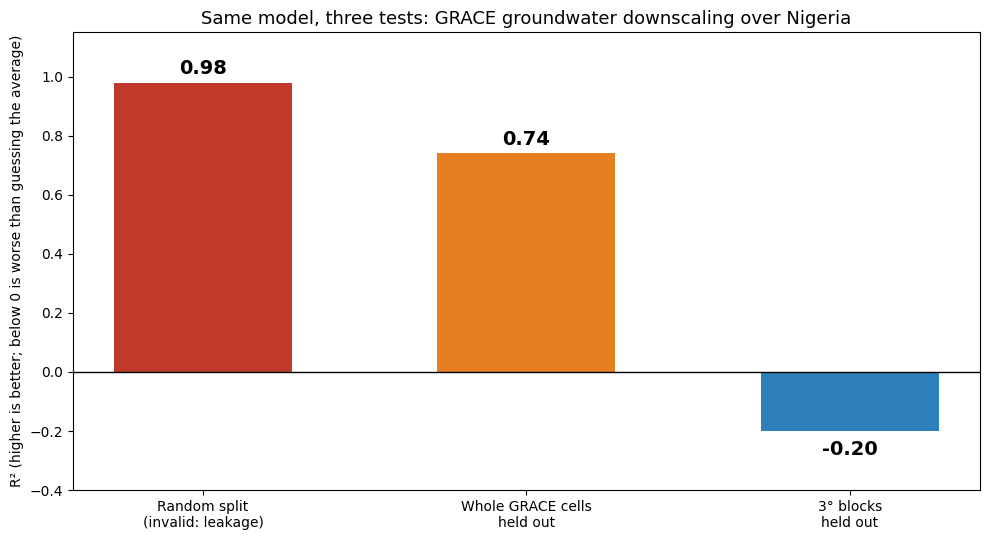

In [25]:
import matplotlib.pyplot as plt

labels = ["Random split\n(invalid: leakage)", "Whole GRACE cells\nheld out", "3° blocks\nheld out"]
vals = [0.98, 0.74, -0.20]
colors = ["#c0392b", "#e67e22", "#2c7fb8"]

fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.bar(labels, vals, color=colors, width=0.55)
ax.axhline(0, color="black", linewidth=1)
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width()/2, v + (0.03 if v >= 0 else -0.08), f"{v:.2f}",
            ha="center", fontsize=14, fontweight="bold")
ax.set_ylim(-0.4, 1.15)
ax.set_ylabel("R² (higher is better; below 0 is worse than guessing the average)")
ax.set_title("Same model, three tests: GRACE groundwater downscaling over Nigeria", fontsize=13)
plt.tight_layout()
plt.savefig("validation_ladder.png", dpi=200)
plt.show()

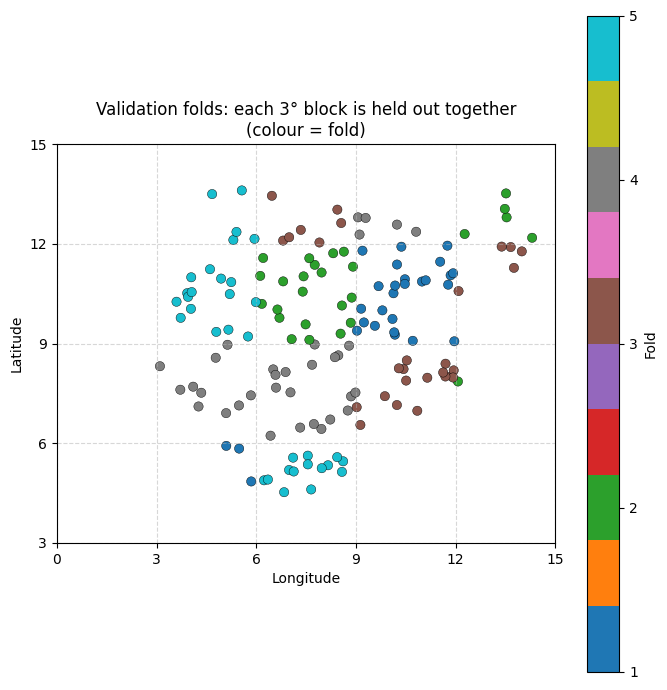

In [26]:
import numpy as np
from sklearn.model_selection import GroupKFold

fold = np.zeros(len(df2), dtype=int)
for k, (a, b) in enumerate(GroupKFold(5).split(df2, groups=df2['block'])):
    fold[b] = k + 1
df2['fold'] = fold
pl = df2.drop_duplicates('place_id')

fig, ax = plt.subplots(figsize=(7, 7))
sc = ax.scatter(pl.Longitude, pl.Latitude, c=pl.fold, cmap="tab10", s=45, edgecolor="k", linewidth=0.3)
ax.set_xticks(np.arange(0, 18, 3)); ax.set_yticks(np.arange(3, 18, 3))
ax.grid(True, linestyle="--", alpha=0.5)
ax.set_aspect("equal")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.set_title("Validation folds: each 3° block is held out together\n(colour = fold)")
plt.colorbar(sc, ticks=[1, 2, 3, 4, 5], label="Fold")
plt.tight_layout()
plt.savefig("fold_map.png", dpi=200)
plt.show()

In [27]:
try:
    print("df2 rows:", df2.shape)
    print(sorted(df2['date'].unique())[:5], "...", sorted(df2['date'].unique())[-5:])
except NameError:
    print("df2 is missing, so the runtime was reset")

df2 rows: (17874, 18)
['2003-02', '2003-03', '2003-04', '2003-07', '2003-08'] ... ['2015-08', '2016-01', '2016-02', '2016-06', '2016-12']


In [28]:
start = ee.Date('2015-08-01')

def rain_window(months_back):
    # total rainfall from (months_back) months before August, through the end of August
    return chirps.filterDate(start.advance(-months_back, 'month'), start.advance(1, 'month')).sum()

rain_cur  = rain_window(0).rename('Rainfall_mm')
rain_prev = chirps.filterDate(start.advance(-1, 'month'), start).sum().rename('Rain_prev')
rain_3m   = rain_window(2).rename('Rain_3m')
rain_6m   = rain_window(5).rename('Rain_6m')
rain_12m  = rain_window(11).rename('Rain_12m')
temp = lst.filterDate(start, start.advance(1, 'month')).mean().multiply(0.02).subtract(273.15).rename('LST_Celsius')
srtm = ee.Image("USGS/SRTMGL1_003")
elev = srtm.rename('Elevation_m')
slope = ee.Terrain.slope(srtm).rename('Slope_deg')

grid_img = ee.Image.cat([rain_cur, rain_prev, rain_3m, rain_6m, rain_12m, temp, elev, slope]).clip(nigeria.geometry())
print(grid_img.bandNames().getInfo())
counts = grid_img.reduceRegion(ee.Reducer.count(), nigeria.geometry(), 5566, maxPixels=1e9).getInfo()
print(counts)

['Rainfall_mm', 'Rain_prev', 'Rain_3m', 'Rain_6m', 'Rain_12m', 'LST_Celsius', 'Elevation_m', 'Slope_deg']
{'Elevation_m': 29960, 'LST_Celsius': 15913, 'Rain_12m': 29951, 'Rain_3m': 29951, 'Rain_6m': 29951, 'Rain_prev': 29951, 'Rainfall_mm': 29951, 'Slope_deg': 29960}


In [29]:
lst_aug = lst.filter(ee.Filter.calendarRange(2003, 2016, 'year')).filter(ee.Filter.calendarRange(8, 8, 'month'))
temp_clim = lst_aug.mean().multiply(0.02).subtract(273.15).rename('LST_Celsius')
temp_filled = temp.unmask(temp_clim)

grid_img = ee.Image.cat([rain_cur, rain_prev, rain_3m, rain_6m, rain_12m, temp_filled, elev, slope]).clip(nigeria.geometry())
counts = grid_img.reduceRegion(ee.Reducer.count(), nigeria.geometry(), 5566, maxPixels=1e9).getInfo()
print(counts)

{'Elevation_m': 29960, 'LST_Celsius': 29941, 'Rain_12m': 29951, 'Rain_3m': 29951, 'Rain_6m': 29951, 'Rain_prev': 29951, 'Rainfall_mm': 29951, 'Slope_deg': 29960}


In [30]:
lst_aug = lst.filter(ee.Filter.calendarRange(2003, 2016, 'year')).filter(ee.Filter.calendarRange(8, 8, 'month'))
temp_clim = lst_aug.mean().multiply(0.02).subtract(273.15).rename('LST_Celsius')
temp_filled = temp.unmask(temp_clim)

grid_img = ee.Image.cat([rain_cur, rain_prev, rain_3m, rain_6m, rain_12m, temp_filled, elev, slope]).clip(nigeria.geometry())
counts = grid_img.reduceRegion(ee.Reducer.count(), nigeria.geometry(), 5566, maxPixels=1e9).getInfo()
print(counts)


{'Elevation_m': 29960, 'LST_Celsius': 29941, 'Rain_12m': 29951, 'Rain_3m': 29951, 'Rain_6m': 29951, 'Rain_prev': 29951, 'Rainfall_mm': 29951, 'Slope_deg': 29960}


{'Elevation_m': 29960, 'LST_Celsius': 29960, 'Rain_12m': 29960, 'Rain_3m': 29960, 'Rain_6m': 29960, 'Rain_prev': 29960, 'Rainfall_mm': 29960, 'Slope_deg': 29960, 'latitude': 29960, 'longitude': 29960}
before dropping gaps: (29960, 10)
after dropping gaps: (29932, 10)
     longitude  latitude
min       2.73      4.28
max      14.63     13.88
               mean    min     max
Elevation_m   330.6   -2.0  1787.0
LST_Celsius    28.5   -7.1    42.0
Rain_12m     1119.0  108.5  3365.7
Rain_3m       588.4   30.2  1560.0
Rain_6m       764.4   56.4  2045.5
Rain_prev     193.8    8.8   679.4
Rainfall_mm   283.0    9.2   679.5
Slope_deg       0.4    0.0     8.8
latitude        9.6    4.3    13.9
longitude       8.1    2.7    14.6


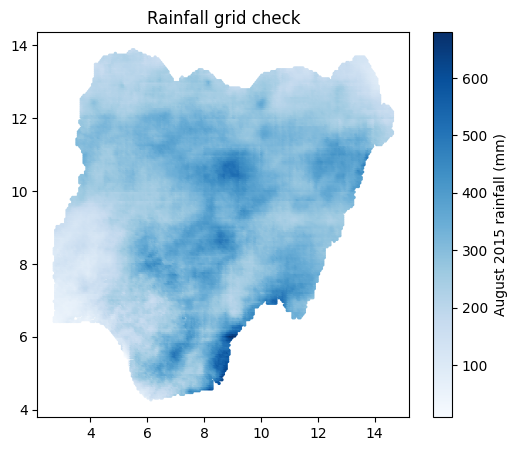

In [34]:
ll = ee.Image.pixelLonLat()
res = grid_img.unmask(-9999).addBands(ll).reduceRegion(
    reducer=ee.Reducer.toList(), geometry=nigeria.geometry(), scale=5566, maxPixels=1e9
).getInfo()

print({k: len(v) for k, v in res.items()})       # all lengths should now be identical

grid_df = pd.DataFrame(res).replace(-9999, np.nan)
print("before dropping gaps:", grid_df.shape)
grid_df = grid_df.dropna().reset_index(drop=True)
print("after dropping gaps:", grid_df.shape)
print(grid_df[['longitude', 'latitude']].agg(['min', 'max']).round(2))
print(grid_df.describe().round(1).T[['mean', 'min', 'max']])

plt.figure(figsize=(6, 5))
plt.scatter(grid_df.longitude, grid_df.latitude, c=grid_df.Rainfall_mm, s=2, cmap='Blues')
plt.colorbar(label='August 2015 rainfall (mm)')
plt.title('Rainfall grid check')
plt.show()

15 grid pixels below 15 C, of 29932
training table LST range: 6.0 to 46.6
3 training rows below 15 C, of 17874


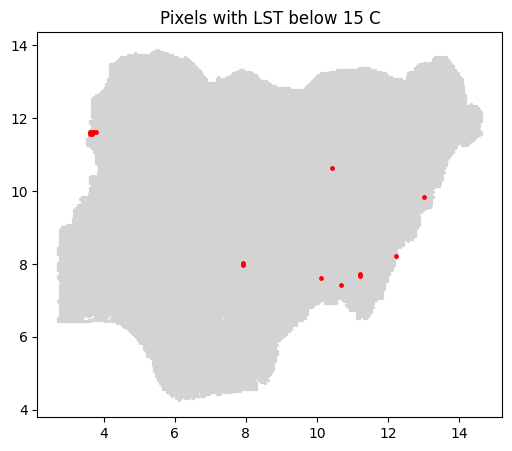

In [35]:
print((grid_df.LST_Celsius < 15).sum(), "grid pixels below 15 C, of", len(grid_df))
print("training table LST range:", round(df2.LST_Celsius.min(), 1), "to", round(df2.LST_Celsius.max(), 1))
print((df2.LST_Celsius < 15).sum(), "training rows below 15 C, of", len(df2))

plt.figure(figsize=(6, 5))
plt.scatter(grid_df.longitude, grid_df.latitude, c='lightgrey', s=2)
cold = grid_df[grid_df.LST_Celsius < 15]
plt.scatter(cold.longitude, cold.latitude, c='red', s=6)
plt.title('Pixels with LST below 15 C')
plt.show()

grid pixels kept: 29917
count    29917.0000
mean         0.1440
std          0.0208
min          0.0618
25%          0.1312
50%          0.1450
75%          0.1584
max          0.2049
Name: TWSA_pred, dtype: float64
Real GRACE value, Aug 2015, at the 150 places: [0.1836 0.1884 0.1047 0.1618 0.1828 0.1829]


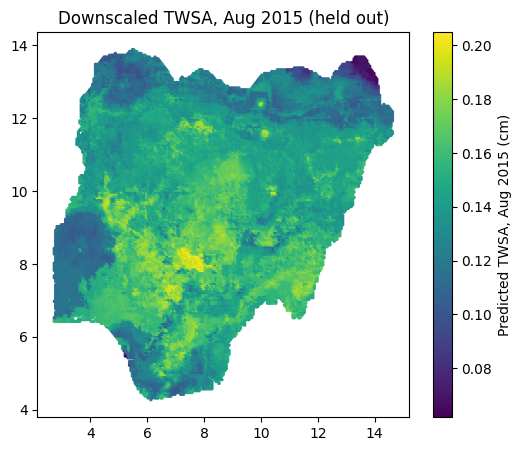

In [44]:
from sklearn.ensemble import RandomForestRegressor
grid_df = grid_df[grid_df.LST_Celsius >= 15].reset_index(drop=True)
print("grid pixels kept:", len(grid_df))

train = df2[df2['date'] != '2015-08'].copy()
cols = ['Rainfall_mm', 'Rain_prev', 'Rain_3m', 'Rain_6m', 'Rain_12m', 'LST_Celsius']
clim = {c: train.groupby('cal_month')[c].mean() for c in cols + ['TWSA']}
for c in cols + ['TWSA']:
    train[c + '_a'] = train[c] - train['cal_month'].map(clim[c])
feats = [c + '_a' for c in cols] + ['Elevation_m', 'Slope_deg']

model = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=42, n_jobs=-1)
model.fit(train[feats], train['TWSA_a'])

g = grid_df.copy()
for c in cols:
    g[c + '_a'] = g[c] - clim[c][8]
g['TWSA_pred'] = clim['TWSA'][8] + model.predict(g[feats])

print(g['TWSA_pred'].describe().round(4))
print("Real GRACE value, Aug 2015, at the 150 places:", df2[df2.date == '2015-08'].TWSA.round(4).unique()[:6])

plt.figure(figsize=(6, 5))
plt.scatter(g.longitude, g.latitude, c=g.TWSA_pred, s=2, cmap='viridis')
plt.colorbar(label='Predicted TWSA, Aug 2015 (cm)')
plt.title('Downscaled TWSA, Aug 2015 (held out)')
plt.show()

In [37]:
grace_aug = grace.filterDate('2015-08-01', '2015-09-01').first().rename('TWSA_true')
r = grace_aug.addBands(ee.Image.pixelLonLat()).unmask(-9999).reduceRegion(
    reducer=ee.Reducer.toList(), geometry=nigeria.geometry(), scale=5566, maxPixels=1e9).getInfo()
true_df = pd.DataFrame(r).replace(-9999, np.nan)

true_df['lon_k'] = true_df.longitude.round(5); true_df['lat_k'] = true_df.latitude.round(5)
g['lon_k'] = g.longitude.round(5); g['lat_k'] = g.latitude.round(5)
m = g.merge(true_df[['lon_k', 'lat_k', 'TWSA_true']], on=['lon_k', 'lat_k']).dropna(subset=['TWSA_true'])
print(len(m), "pixels matched")

cell = m.groupby(m.TWSA_true.round(6)).agg(
    true=('TWSA_true', 'first'), pred_mean=('TWSA_pred', 'mean'), n=('TWSA_pred', 'size')).reset_index(drop=True)
cell = cell[cell.n >= 20]                      # skip sliver cells at the border
const = clim['TWSA'][8]                         # the dumb baseline: August normal everywhere

print(len(cell), "GRACE cells compared")
print("RMSE model   :", round(np.sqrt(((cell.pred_mean - cell.true)**2).mean()), 4))
print("RMSE constant:", round(np.sqrt(((const - cell.true)**2).mean()), 4))
print("Correlation  :", round(np.corrcoef(cell.pred_mean, cell.true)[0, 1], 3))
print(cell.round(3).sort_values('true').to_string())

0 pixels matched
0 GRACE cells compared
RMSE model   : nan
RMSE constant: nan
Correlation  : nan
Empty DataFrame
Columns: [true, pred_mean, n]
Index: []


/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:562: RuntimeWarning: Mean of empty slice.
  avg = a.mean(axis, **keepdims_kw)
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:139: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2991: RuntimeWarning: Degrees of freedom <= 0 for slice
  c = cov(x, y, rowvar, dtype=dtype)
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2848: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2848: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide(1, fact)


In [38]:
grace_aug = grace.filterDate('2015-08-01', '2015-09-01').first().rename('TWSA_true')
full = grid_img.addBands(grace_aug).unmask(-9999).addBands(ee.Image.pixelLonLat())
res = full.reduceRegion(reducer=ee.Reducer.toList(), geometry=nigeria.geometry(),
                        scale=5566, maxPixels=1e9).getInfo()
grid_df = pd.DataFrame(res).replace(-9999, np.nan).dropna().reset_index(drop=True)
print(grid_df.shape)
print(grid_df.TWSA_true.nunique(), "distinct GRACE values")
print(sorted(grid_df.TWSA_true.round(4).unique())[:8])

(29932, 11)
99 distinct GRACE values
[np.float64(0.0667), np.float64(0.0672), np.float64(0.0676), np.float64(0.0679), np.float64(0.0713), np.float64(0.0762), np.float64(0.0785), np.float64(0.0825)]


In [40]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor

# 1. Drop the 15 suspect cold-temperature pixels
grid_df = grid_df[grid_df.LST_Celsius >= 15].reset_index(drop=True)
print("grid pixels kept:", len(grid_df))

# 2. Training data: every month except August 2015
train = df2[df2['date'] != '2015-08'].copy()
cols = ['Rainfall_mm', 'Rain_prev', 'Rain_3m', 'Rain_6m', 'Rain_12m', 'LST_Celsius']

# 3. Normal (average) for each calendar month, then each value as "difference from normal"
clim = {c: train.groupby('cal_month')[c].mean() for c in cols + ['TWSA']}
for c in cols + ['TWSA']:
    train[c + '_a'] = train[c] - train['cal_month'].map(clim[c])
feats = [c + '_a' for c in cols] + ['Elevation_m', 'Slope_deg']

# 4. Train on the differences
model = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=42, n_jobs=-1)
model.fit(train[feats], train['TWSA_a'])

# 5. Predict every grid pixel: subtract August's normal, predict, add the normal back
g = grid_df.copy()
for c in cols:
    g[c + '_a'] = g[c] - clim[c][8]
g['TWSA_pred'] = clim['TWSA'][8] + model.predict(g[feats])
print(g['TWSA_pred'].describe().round(4))

grid pixels kept: 29917
count    29917.0000
mean         0.1440
std          0.0208
min          0.0618
25%          0.1312
50%          0.1450
75%          0.1584
max          0.2049
Name: TWSA_pred, dtype: float64


In [41]:
# Group pixels by their GRACE cell: every pixel in one 1-degree cell shares one true value
cell = g.groupby(g.TWSA_true.round(6)).agg(
    true=('TWSA_true', 'first'), pred_mean=('TWSA_pred', 'mean'), n=('TWSA_pred', 'size')).reset_index(drop=True)
cell = cell[cell.n >= 20]                       # skip thin border cells
const = clim['TWSA'][8]                         # the "dumb" baseline: August normal everywhere

print(len(cell), "GRACE cells compared")
print("RMSE model   :", round(np.sqrt(((cell.pred_mean - cell.true)**2).mean()), 4))
print("RMSE constant:", round(np.sqrt(((const - cell.true)**2).mean()), 4))
print("Correlation  :", round(np.corrcoef(cell.pred_mean, cell.true)[0, 1], 3))
print(cell.round(3).sort_values('true').to_string())

94 GRACE cells compared
RMSE model   : 0.0328
RMSE constant: 0.0375
Correlation  : 0.514
     true  pred_mean    n
0   0.067      0.133   81
1   0.067      0.126   96
2   0.068      0.125  208
3   0.068      0.129  257
5   0.076      0.082  227
6   0.078      0.126   63
7   0.083      0.112   93
9   0.088      0.136  219
10  0.090      0.105  135
11  0.091      0.121  305
12  0.095      0.116  105
13  0.096      0.112  129
14  0.097      0.148  400
15  0.098      0.127  120
16  0.100      0.155  290
17  0.102      0.147  398
18  0.105      0.113  400
19  0.105      0.142  341
20  0.106      0.122  400
22  0.112      0.149  400
23  0.114      0.124  400
24  0.118      0.123   40
25  0.119      0.133  160
26  0.119      0.150  395
27  0.120      0.113  104
28  0.124      0.155  399
29  0.124      0.127  400
30  0.129      0.111  399
31  0.130      0.128   72
32  0.131      0.141  386
33  0.132      0.160  392
34  0.133      0.163  400
35  0.134      0.124  400
36  0.138      0.150  399
3

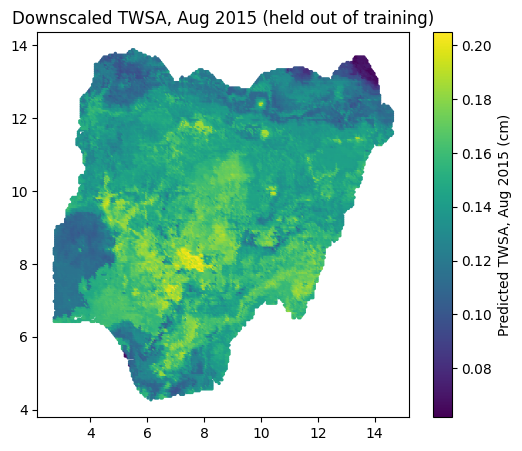

In [45]:
plt.figure(figsize=(6, 5))
plt.scatter(g.longitude, g.latitude, c=g.TWSA_pred, s=2, cmap='viridis')
plt.colorbar(label='Predicted TWSA, Aug 2015 (cm)')
plt.title('Downscaled TWSA, Aug 2015 (held out of training)')
plt.savefig('downscaled_map.png', dpi=200, bbox_inches='tight')
plt.show()


In [46]:
import os
print([f for f in os.listdir() if f.endswith('.png')])

['downscaled_map.png', 'fold_map.png', 'consistency_check.png', 'validation_ladder.png']
